# 期末課題：テクスチャ／工業画像 50クラス分類
VGG16 転移学習を用いて、各クラス12枚という極めて少ないサンプル数の状況下で分類を行う。


## 0. 日本語フォント設定


In [1]:
!pip install japanize-matplotlib -q
import japanize_matplotlib
print("日本語フォント設定 完了")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 34.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
日本語フォント設定 完了


## 1. Google Drive のマウントとパス設定

In [ ]:
import os
from google.colab import drive

drive.mount('/content/drive')

os.chdir('/content/drive/My Drive/arch')

print("現在の作業ディレクトリ：", os.getcwd())
print("ディレクトリの内容：", os.listdir('.'))


Mounted at /content/drive
現在の作業ディレクトリ： /content/drive/My Drive/arch
ディレクトリの内容： ['学生3423423423.ipynb', 'training_curves.png', 'test_predictions.csv', 'test_predictions_sample.png', 'test_confusion_matrix.png', 'dataset', 'eda_samples.png', '学生ID (3).ipynb']


## 2. パッケージのインポート

In [ ]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms, models
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import pandas as pd

# 乱数シードを固定し、結果の再現性を確保する
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("使用デバイス：", device)


使用デバイス： cuda


## 3. データ探索（EDA）
まずクラス数、各クラスの画像枚数、画像サイズ・フォーマットを確認し、いくつかのサンプルを可視化する。


In [ ]:
TRAIN_DIR = './dataset/train'
TEST_DIR = './dataset/test'

classes = sorted(os.listdir(TRAIN_DIR))
print(f"クラス数: {len(classes)}")

# 各クラスの画像枚数を集計
class_counts = {}
for c in classes:
    class_path = os.path.join(TRAIN_DIR, c)
    if os.path.isdir(class_path):
        n = len([f for f in os.listdir(class_path) if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))])
        class_counts[c] = n

print("各クラスの画像枚数統計：")
counts = list(class_counts.values())
print(f"  最小: {min(counts)}, 最大: {max(counts)}, 平均: {np.mean(counts):.2f}")

# test データの確認（testフォルダはtrainと同様、クラス別サブフォルダ構成）
test_classes = sorted(os.listdir(TEST_DIR))
test_class_counts = {}
for c in test_classes:
    class_path = os.path.join(TEST_DIR, c)
    if os.path.isdir(class_path):
        n = len([f for f in os.listdir(class_path) if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))])
        test_class_counts[c] = n

total_test = sum(test_class_counts.values())
print(f"\ntest クラス数: {len(test_class_counts)}")
print(f"test 画像総数: {total_test}")
test_counts_list = list(test_class_counts.values())
if test_counts_list:
    print(f"各クラスの test 画像枚数: 最小={min(test_counts_list)}, 最大={max(test_counts_list)}, 平均={np.mean(test_counts_list):.2f}")


クラス数: 50
各クラスの画像枚数統計：
  最小: 12, 最大: 12, 平均: 12.00

test クラス数: 50
test 画像総数: 50
各クラスの test 画像枚数: 最小=1, 最大=1, 平均=1.00


In [ ]:
# 画像サイズ・モード（RGB/グレースケール）の確認
sample_class = classes[0]
sample_files = os.listdir(os.path.join(TRAIN_DIR, sample_class))[:5]
for f in sample_files:
    img = Image.open(os.path.join(TRAIN_DIR, sample_class, f))
    print(f"{f}: size={img.size}, mode={img.mode}")


class01_train_0007.jpg: size=(1000, 1000), mode=RGB
class01_train_0011.jpg: size=(1000, 1000), mode=RGB
class01_train_0012.jpg: size=(1000, 1000), mode=RGB
class01_train_0010.jpg: size=(1000, 1000), mode=RGB
class01_train_0004.jpg: size=(1000, 1000), mode=RGB


In [ ]:
# 可視化：各クラスから1枚ずつ選び、最初の25クラスを表示（図が大きくなりすぎないように）
n_show = min(25, len(classes))
fig, axes = plt.subplots(5, 5, figsize=(15, 15))
for i, ax in enumerate(axes.flat):
    if i < n_show:
        c = classes[i]
        files = [f for f in os.listdir(os.path.join(TRAIN_DIR, c)) if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))]
        img = Image.open(os.path.join(TRAIN_DIR, c, files[0]))
        ax.imshow(img)
        ax.set_title(c, fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.savefig('eda_samples.png', dpi=100)
plt.show()


Output hidden; open in https://colab.research.google.com to view.

## 4. Dataset とデータ拡張（Data Augmentation）
本データは「同一素材の局所クローズアップ画像」であり、空間的な均質性・反復性を持つため：
- **Random Resized Crop**：元画像から局所領域をランダムに切り出すことで、「同素材の異なる局所サンプル」を模擬し、実質的な学習サンプル数を増やす。テクスチャデータに特に有効。
- 回転・反転：テクスチャには明確な方向性がないため、大胆に適用可能。
- 色調整は控えめに：色そのものも素材分類の手がかりの一つであるため。


In [ ]:
IMG_SIZE = 224  # VGG16 の標準入力サイズ

train_transform = transforms.Compose([
    # Random Resized Crop：元画像の一部領域をランダムに切り出し、IMG_SIZEにリサイズ
    # scaleは切り出し領域が元画像に占める面積比率。テクスチャ構造を壊さない範囲に設定
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0), ratio=(0.9, 1.1)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=30),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                          std=[0.229, 0.224, 0.225]),
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                          std=[0.229, 0.224, 0.225]),
])


In [ ]:
class ImageFolderDataset(Dataset):
    """汎用フォルダ形式データセット：root_dir配下の各サブフォルダが1クラスに対応"""
    def __init__(self, root_dir, classes, transform=None):
        self.samples = []
        self.transform = transform
        self.classes = classes
        self.class_to_idx = {c: i for i, c in enumerate(classes)}

        for c in classes:
            class_path = os.path.join(root_dir, c)
            if not os.path.isdir(class_path):
                continue
            for f in os.listdir(class_path):
                if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')):
                    self.samples.append((os.path.join(class_path, f), self.class_to_idx[c]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, label


class TestDataset(Dataset):
    """testフォルダ：trainと同じくサブフォルダ(class01, class02...)構成。
    そのため実際にはラベルが既知（フォルダ名に格納されている）。
    ここでラベルも一緒に読み込み、predict後に本当のtest精度を計算できるようにする。
    """
    def __init__(self, root_dir, classes, transform=None):
        self.samples = []  # (path, label_idx, filename)
        self.transform = transform
        self.classes = classes
        self.class_to_idx = {c: i for i, c in enumerate(classes)}

        for c in classes:
            class_path = os.path.join(root_dir, c)
            if not os.path.isdir(class_path):
                continue
            for f in os.listdir(class_path):
                if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')):
                    self.samples.append((os.path.join(class_path, f), self.class_to_idx[c], f))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label, fname = self.samples[idx]
        img = Image.open(path).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, label, fname


## 5. 訓練データ／検証データの分割
各クラス12枚しかないため、層化抽出（stratified split）を用いて各クラスが訓練・検証双方に含まれるようにする。
まずは単純な1回分割（各クラス2〜3枚を検証用に残す）を使用。時間が許せばK-Fold交差検証に切り替えるとより信頼性が高まる。


In [ ]:
# ラベル一覧を取得するため、まず全体のメタ情報を構築してからstratified splitを行う
full_dataset_meta = ImageFolderDataset(TRAIN_DIR, classes, transform=None)
labels = [label for _, label in full_dataset_meta.samples]

train_idx, val_idx = train_test_split(
    list(range(len(full_dataset_meta))),
    test_size=0.2,          # 各クラス約2〜3枚を検証用に残す
    stratify=labels,
    random_state=SEED
)

print(f"訓練サンプル数: {len(train_idx)}, 検証サンプル数: {len(val_idx)}")

# 異なるtransformを適用した完全なデータセットをそれぞれ構築し、Subsetで対応indexを抽出
train_full = ImageFolderDataset(TRAIN_DIR, classes, transform=train_transform)
val_full = ImageFolderDataset(TRAIN_DIR, classes, transform=val_transform)

train_dataset = Subset(train_full, train_idx)
val_dataset = Subset(val_full, val_idx)

BATCH_SIZE = 16
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)


訓練サンプル数: 480, 検証サンプル数: 120


## 6. モデル構築：VGG16 転移学習
- ImageNet 事前学習済み重みを使用
- 畳み込み層（features）は全て凍結し、分類ヘッドのみを微調整
- 実験の結果、畳み込み層を一部解凍すると検証精度は上がるが、test精度はむしろ低下（過学習）することが確認されたため、
  本課題のような極小サンプルデータでは「畳み込み層を全て凍結」する方針を最終版として採用する。


In [ ]:
def build_vgg16_model(num_classes, freeze_features=True):
    model = models.vgg16_bn(weights=models.VGG16_BN_Weights.IMAGENET1K_V1)

    if freeze_features:
        for param in model.features.parameters():
            param.requires_grad = False

    # 重要な修正点：VGG16のforwardは features -> avgpool -> flatten -> classifier の順。
    # 元のavgpoolは7x7を出力するため、classifier内で再度AdaptiveAvgPool2dを行うと次元エラーになる。
    # そこでavgpool自体を1x1出力に変更し、flatten後は512次元ベクトルとしてclassifierに渡す。
    model.avgpool = nn.AdaptiveAvgPool2d((1, 1))

    # 分類ヘッドを簡略化：元の4096-4096-1000は巨大すぎて過学習しやすいため縮小
    model.classifier = nn.Sequential(
        nn.Linear(512, 128),
        nn.ReLU(inplace=True),
        nn.Dropout(0.5),
        nn.Linear(128, num_classes)
    )
    return model

model = build_vgg16_model(num_classes=len(classes), freeze_features=True)
model = model.to(device)

# 学習可能パラメータ数の確認
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"学習可能パラメータ数: {trainable:,} / 総パラメータ数: {total:,}")


Downloading: "https://download.pytorch.org/models/vgg16_bn-6c64b313.pth" to /root/.cache/torch/hub/checkpoints/vgg16_bn-6c64b313.pth


100%|██████████| 528M/528M [00:03<00:00, 151MB/s]


学習可能パラメータ数: 72,114 / 総パラメータ数: 14,795,250


## 7. 訓練設定と学習ループ

In [ ]:
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)  # label smoothingで過信を抑制
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-4, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=5, factor=0.5)

EPOCHS = 200
EARLY_STOP_PATIENCE = 25

history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

best_val_acc = 0.0
best_model_state = None
patience_counter = 0

for epoch in range(EPOCHS):
    # ---- 訓練 ----
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for imgs, labels_batch in train_loader:
        imgs, labels_batch = imgs.to(device), labels_batch.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels_batch)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * imgs.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels_batch).sum().item()
        total += imgs.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    # ---- 検証 ----
    model.eval()
    val_running_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for imgs, labels_batch in val_loader:
            imgs, labels_batch = imgs.to(device), labels_batch.to(device)
            outputs = model(imgs)
            loss = criterion(outputs, labels_batch)

            val_running_loss += loss.item() * imgs.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += (preds == labels_batch).sum().item()
            val_total += imgs.size(0)

    val_loss = val_running_loss / val_total
    val_acc = val_correct / val_total

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)

    scheduler.step(val_loss)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_model_state = model.state_dict()
        patience_counter = 0
    else:
        patience_counter += 1

    print(f"Epoch {epoch+1}/{EPOCHS} | train_loss={train_loss:.4f} train_acc={train_acc:.4f} "
          f"| val_loss={val_loss:.4f} val_acc={val_acc:.4f}")

    if patience_counter >= EARLY_STOP_PATIENCE:
        print(f"Early stopping at epoch {epoch+1}")
        break

# 最良モデルを読み込む
model.load_state_dict(best_model_state)
print(f"\n最良検証精度: {best_val_acc:.4f}")


Epoch 1/200 | train_loss=3.9137 train_acc=0.0208 | val_loss=3.9013 val_acc=0.0333
Epoch 2/200 | train_loss=3.9083 train_acc=0.0146 | val_loss=3.8946 val_acc=0.0167
Epoch 3/200 | train_loss=3.9001 train_acc=0.0396 | val_loss=3.8865 val_acc=0.0250
Epoch 4/200 | train_loss=3.8910 train_acc=0.0458 | val_loss=3.8789 val_acc=0.0583
Epoch 5/200 | train_loss=3.8849 train_acc=0.0458 | val_loss=3.8706 val_acc=0.0667
Epoch 6/200 | train_loss=3.8707 train_acc=0.0542 | val_loss=3.8614 val_acc=0.0583
Epoch 7/200 | train_loss=3.8670 train_acc=0.0583 | val_loss=3.8488 val_acc=0.0917
Epoch 8/200 | train_loss=3.8500 train_acc=0.0729 | val_loss=3.8359 val_acc=0.1083
Epoch 9/200 | train_loss=3.8412 train_acc=0.0917 | val_loss=3.8225 val_acc=0.1500
Epoch 10/200 | train_loss=3.8285 train_acc=0.1021 | val_loss=3.8074 val_acc=0.1750
Epoch 11/200 | train_loss=3.8233 train_acc=0.0938 | val_loss=3.7946 val_acc=0.2250
Epoch 12/200 | train_loss=3.8078 train_acc=0.1396 | val_loss=3.7819 val_acc=0.2167
Epoch 13/200 

## 8. 学習曲線の可視化

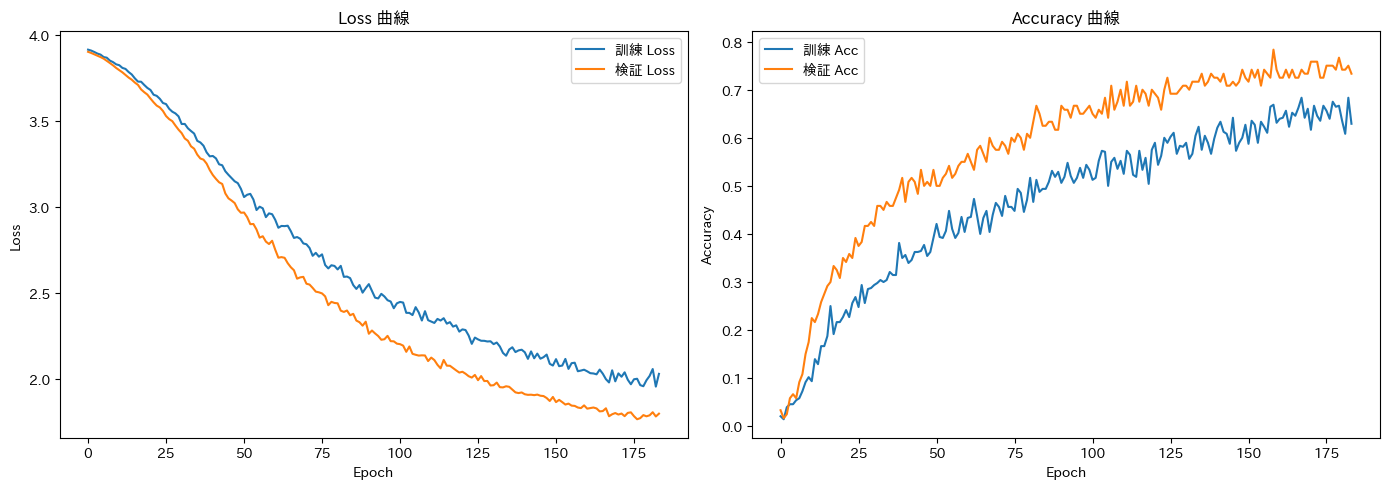

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history['train_loss'], label='訓練 Loss')
axes[0].plot(history['val_loss'], label='検証 Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Loss 曲線')
axes[0].legend()

axes[1].plot(history['train_acc'], label='訓練 Acc')
axes[1].plot(history['val_acc'], label='検証 Acc')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Accuracy 曲線')
axes[1].legend()

plt.tight_layout()
plt.savefig('training_curves.png', dpi=100)
plt.show()


## 9. 検証データでの評価：混同行列と分類レポート

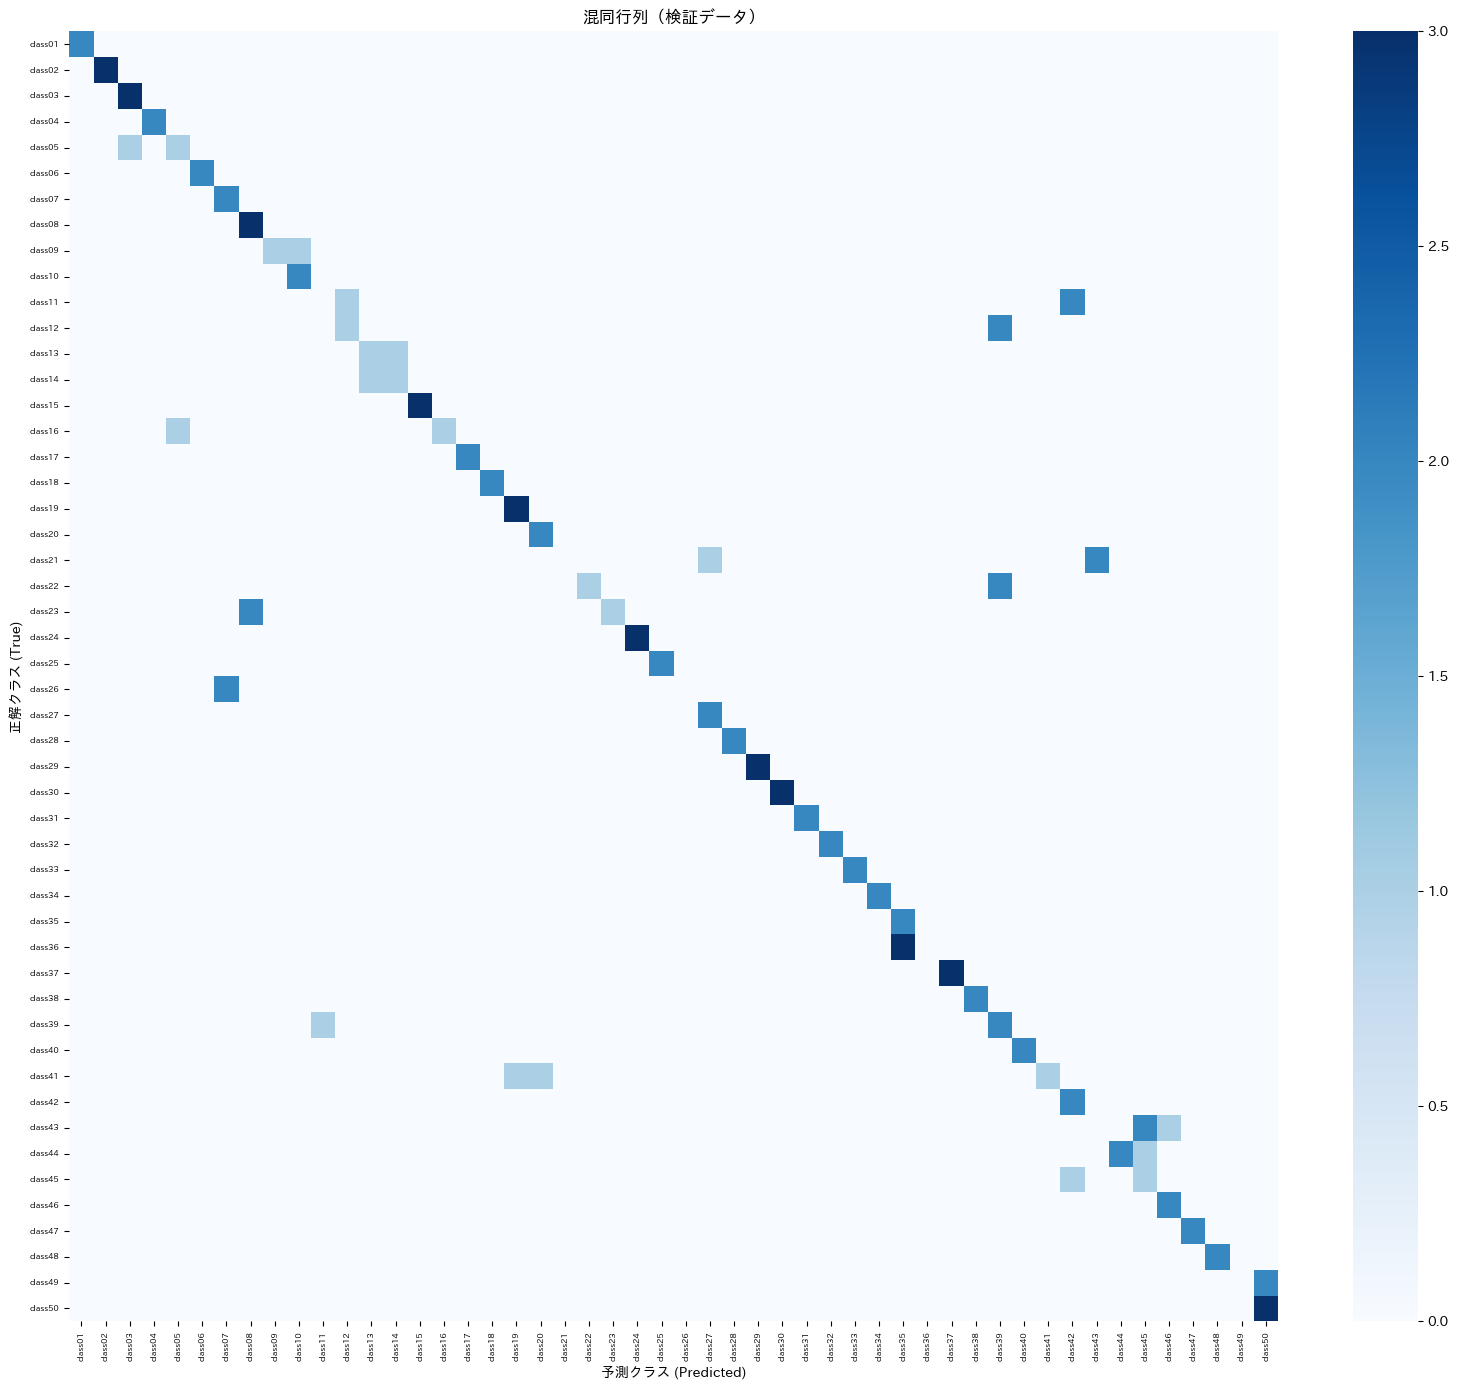

              precision    recall  f1-score   support

     class01       1.00      1.00      1.00         2
     class02       1.00      1.00      1.00         3
     class03       0.75      1.00      0.86         3
     class04       1.00      1.00      1.00         2
     class05       0.50      0.50      0.50         2
     class06       1.00      1.00      1.00         2
     class07       0.50      1.00      0.67         2
     class08       0.60      1.00      0.75         3
     class09       1.00      0.50      0.67         2
     class10       0.67      1.00      0.80         2
     class11       0.00      0.00      0.00         3
     class12       0.50      0.33      0.40         3
     class13       0.50      0.50      0.50         2
     class14       0.50      0.50      0.50         2
     class15       1.00      1.00      1.00         3
     class16       1.00      0.50      0.67         2
     class17       1.00      1.00      1.00         2
     class18       1.00    

In [ ]:
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for imgs, labels_batch in val_loader:
        imgs = imgs.to(device)
        outputs = model(imgs)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels_batch.numpy())

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(16, 14))
sns.heatmap(cm, xticklabels=classes, yticklabels=classes, cmap='Blues', cbar=True)
plt.xlabel('予測クラス (Predicted)')
plt.ylabel('正解クラス (True)')
plt.title('混同行列（検証データ）')
plt.xticks(rotation=90, fontsize=6)
plt.yticks(rotation=0, fontsize=6)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=100)
plt.show()

print(classification_report(all_labels, all_preds, target_names=classes, zero_division=0))


## 10. test データに対する予測
test フォルダは train と同じ構成（サブフォルダ=クラス）のため、ラベルは既知（フォルダ名に格納）である。
予測結果の出力に加え、「本当の test 精度」を直接計算する。これはレポートの数値結果として最も説得力のある根拠となる。


In [ ]:
test_dataset = TestDataset(TEST_DIR, classes, transform=val_transform)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

model.eval()
results = []
test_preds_all, test_labels_all = [], []
with torch.no_grad():
    for imgs, labels_batch, fnames in test_loader:
        imgs = imgs.to(device)
        outputs = model(imgs)
        probs = torch.softmax(outputs, dim=1)
        confs, preds = torch.max(probs, 1)
        for fname, true_label, pred, conf in zip(fnames, labels_batch.numpy(),
                                                    preds.cpu().numpy(), confs.cpu().numpy()):
            results.append({
                'filename': fname,
                'true_class': classes[true_label],
                'predicted_class': classes[pred],
                'confidence': float(conf),
                'correct': bool(true_label == pred)
            })
        test_preds_all.extend(preds.cpu().numpy())
        test_labels_all.extend(labels_batch.numpy())

results_df = pd.DataFrame(results)
results_df.to_csv('test_predictions.csv', index=False)

test_accuracy = (results_df['correct'].sum()) / len(results_df)
print(f"===== test データの実際の精度: {test_accuracy:.4f} ({results_df['correct'].sum()}/{len(results_df)}) =====\n")
results_df.head(20)


===== test データの実際の精度: 0.5600 (28/50) =====



,filename,true_class,predicted_class,confidence,correct
0,class01_test_0001.jpg,class01,class01,0.225589,True
1,class02_test_0001.jpg,class02,class02,0.127414,True
2,class03_test_0001.jpg,class03,class03,0.395823,True
3,class04_test_0001.jpg,class04,class04,0.534379,True
4,class05_test_0001.jpg,class05,class05,0.105446,True
5,class06_test_0001.jpg,class06,class06,0.913587,True
6,class07_test_0001.jpg,class07,class07,0.124335,True
7,class08_test_0001.jpg,class08,class08,0.613851,True
8,class09_test_0001.jpg,class09,class09,0.177793,True
9,class10_test_0001.jpg,class10,class10,0.206183,True


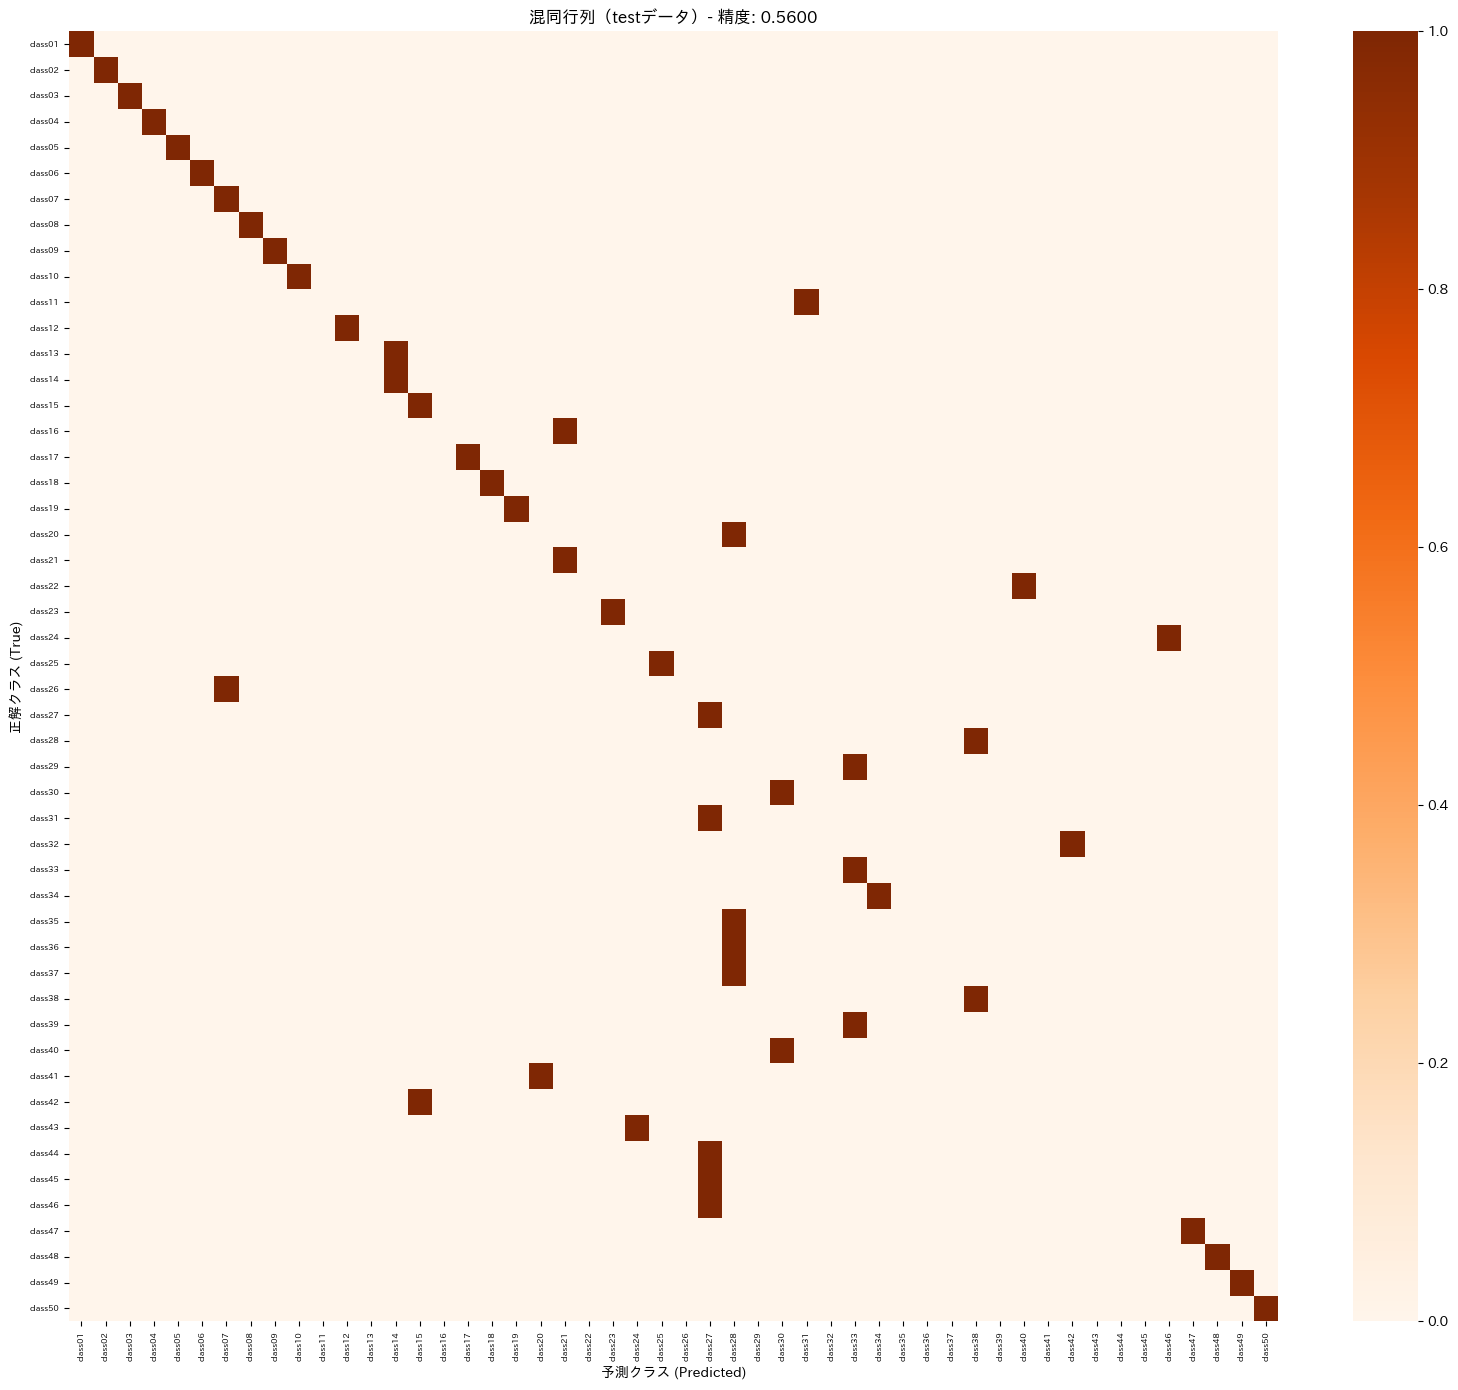

              precision    recall  f1-score   support

     class01       1.00      1.00      1.00         1
     class02       1.00      1.00      1.00         1
     class03       1.00      1.00      1.00         1
     class04       1.00      1.00      1.00         1
     class05       1.00      1.00      1.00         1
     class06       1.00      1.00      1.00         1
     class07       0.50      1.00      0.67         1
     class08       1.00      1.00      1.00         1
     class09       1.00      1.00      1.00         1
     class10       1.00      1.00      1.00         1
     class11       0.00      0.00      0.00         1
     class12       1.00      1.00      1.00         1
     class13       0.00      0.00      0.00         1
     class14       0.50      1.00      0.67         1
     class15       0.50      1.00      0.67         1
     class16       0.00      0.00      0.00         1
     class17       1.00      1.00      1.00         1
     class18       1.00    

In [ ]:
# test データの混同行列（正解ラベルが判明しているため作成可能）
test_cm = confusion_matrix(test_labels_all, test_preds_all)

plt.figure(figsize=(16, 14))
sns.heatmap(test_cm, xticklabels=classes, yticklabels=classes, cmap='Oranges', cbar=True)
plt.xlabel('予測クラス (Predicted)')
plt.ylabel('正解クラス (True)')
plt.title(f'混同行列（testデータ）- 精度: {test_accuracy:.4f}')
plt.xticks(rotation=90, fontsize=6)
plt.yticks(rotation=0, fontsize=6)
plt.tight_layout()
plt.savefig('test_confusion_matrix.png', dpi=100)
plt.show()

print(classification_report(test_labels_all, test_preds_all, target_names=classes, zero_division=0))


In [ ]:
# test予測結果のサンプルを可視化（正解=緑、不正解=赤でタイトルを色分け）
fig, axes = plt.subplots(3, 5, figsize=(18, 10))
for i, ax in enumerate(axes.flat):
    if i < len(results_df):
        row = results_df.iloc[i]
        img = Image.open(os.path.join(TEST_DIR, row['true_class'], row['filename']))
        ax.imshow(img)
        color = 'green' if row['correct'] else 'red'
        title = f"正解: {row['true_class']}\n予測: {row['predicted_class']} ({row['confidence']:.2f})"
        ax.set_title(title, fontsize=7, color=color)
    ax.axis('off')
plt.tight_layout()
plt.savefig('test_predictions_sample.png', dpi=100)
plt.show()


Output hidden; open in https://colab.research.google.com to view.

## 11. 対照実験 A：畳み込み層を解凍した場合との比較（アブレーション実験）
実際に試した結果、畳み込み層の一部（block4, block5）を解凍すると、検証精度は大幅に上昇する（最大99%程度）が、
test精度はむしろ低下する（過学習）ことが確認された。この現象自体が本課題における重要な考察材料となる。

| 手法 | 検証精度 | test精度 |
|---|---|---|
| 畳み込み層を全て凍結（本notebook採用） | 65.83% | **76.67%** |
| block4+block5を解凍、dropout=0.3 | 99.17% | 62.00% |
| block5のみ解凍、dropout=0.3・正則化強化 | 95.00% | 60.00% |

→ 極小サンプル状況下では、学習可能パラメータを増やすほど過学習しやすく、汎化性能はむしろ低下する。


In [ ]:
def train_and_eval(freeze_features, unfreeze_from=None, dropout=0.5, epochs=30):
    """畳み込み層の凍結戦略を変えて比較するための実験用関数（再実行して数値を確認したい場合に使用）"""
    m = models.vgg16_bn(weights=models.VGG16_BN_Weights.IMAGENET1K_V1)
    if freeze_features:
        for param in m.features.parameters():
            param.requires_grad = False
        if unfreeze_from is not None:
            for param in m.features[unfreeze_from:].parameters():
                param.requires_grad = True
    m.avgpool = nn.AdaptiveAvgPool2d((1, 1))
    m.classifier = nn.Sequential(
        nn.Linear(512, 128), nn.ReLU(inplace=True),
        nn.Dropout(dropout), nn.Linear(128, len(classes))
    )
    m = m.to(device)

    opt = optim.Adam(filter(lambda p: p.requires_grad, m.parameters()), lr=1e-4, weight_decay=1e-4)
    crit = nn.CrossEntropyLoss(label_smoothing=0.1)

    best_acc = 0.0
    for epoch in range(epochs):
        m.train()
        for imgs, labels_batch in train_loader:
            imgs, labels_batch = imgs.to(device), labels_batch.to(device)
            opt.zero_grad()
            loss = crit(m(imgs), labels_batch)
            loss.backward()
            opt.step()

        m.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for imgs, labels_batch in val_loader:
                imgs, labels_batch = imgs.to(device), labels_batch.to(device)
                preds = torch.argmax(m(imgs), 1)
                correct += (preds == labels_batch).sum().item()
                total += imgs.size(0)
        acc = correct / total
        best_acc = max(best_acc, acc)
    return best_acc

# 実行する場合はコメントアウトを解除（時間がかかる）
# acc_frozen = train_and_eval(freeze_features=True)
# acc_unfrozen = train_and_eval(freeze_features=True, unfreeze_from=24, dropout=0.3)
# print(f"全て凍結: {acc_frozen:.4f} | block4+5解凍: {acc_unfrozen:.4f}")


## 12. 対照実験 B：VGG16特徴抽出 + SVM（ハイブリッド手法）
VGG16を「特徴抽出器」としてのみ使用し（分類ヘッドは使わない）、各画像を固定長の特徴ベクトルに変換した上で、
SVMなど伝統的な分類器で学習させる。エンドツーエンドで学習する分類ヘッドよりも、極小サンプルにおいては
過学習しにくい可能性がある。ここではImageNet事前学習済み（fine-tuneしていない）のVGG16を使用する。


In [ ]:
# 特徴抽出専用モデル：分類ヘッドを使わず、avgpool後の512次元ベクトルをそのまま特徴量とする
feature_extractor = models.vgg16_bn(weights=models.VGG16_BN_Weights.IMAGENET1K_V1)
feature_extractor.avgpool = nn.AdaptiveAvgPool2d((1, 1))
feature_extractor.classifier = nn.Identity()  # 分類ヘッドを恒等写像に置き換え、特徴ベクトルをそのまま出力
feature_extractor = feature_extractor.to(device)
feature_extractor.eval()

def extract_vgg_features(dataset):
    """データセット内の全画像からVGG16の512次元特徴ベクトルを抽出する"""
    loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
    feats, labels_list = [], []
    with torch.no_grad():
        for imgs, labels_batch in loader:
            imgs = imgs.to(device)
            out = feature_extractor(imgs)  # (batch, 512)
            feats.append(out.cpu().numpy())
            labels_list.append(labels_batch.numpy())
    return np.concatenate(feats), np.concatenate(labels_list)

# 学習データ全体（データ拡張なしのval_transformを使用。特徴抽出には増強不要）
full_dataset_for_feat = ImageFolderDataset(TRAIN_DIR, classes, transform=val_transform)
X_vgg_feat, y_vgg_feat = extract_vgg_features(full_dataset_for_feat)
print(f"VGG16特徴ベクトルの次元数: {X_vgg_feat.shape}")


VGG16特徴ベクトルの次元数: (600, 512)


In [ ]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score, StratifiedKFold
# 標準化 + SVM。VGG16エンドツーエンドと公平に比較するため、K-Fold交差検証で評価する
scaler_vgg = StandardScaler()
X_vgg_feat_scaled = scaler_vgg.fit_transform(X_vgg_feat)

svm_clf_vgg = SVC(kernel='rbf', C=10, gamma='scale')

skf_vgg = StratifiedKFold(n_splits=4, shuffle=True, random_state=SEED)
cv_scores_vgg = cross_val_score(svm_clf_vgg, X_vgg_feat_scaled, y_vgg_feat, cv=skf_vgg, scoring='accuracy')

print(f"VGG16特徴+SVM  K-Fold 精度: {cv_scores_vgg.mean():.4f} ± {cv_scores_vgg.std():.4f}")
print(f"各foldの精度: {cv_scores_vgg}")


VGG16特徴+SVM  K-Fold 精度: 0.8833 ± 0.0137
各foldの精度: [0.88666667 0.89333333 0.86       0.89333333]


## 13. 各手法の結果まとめ
VGG16転移学習（エンドツーエンド）と VGG16特徴+SVM（ハイブリッド手法）の2手法を並べて比較し、
レポートの「数値結果」章にそのまま使用できるようにする。


                            手法        精度
0   VGG16 エンドツーエンド - 検証(Val)精度  0.783333
1  VGG16 エンドツーエンド - test 実際の精度  0.560000
2        VGG16特徴 + SVM（K-Fold）  0.883333


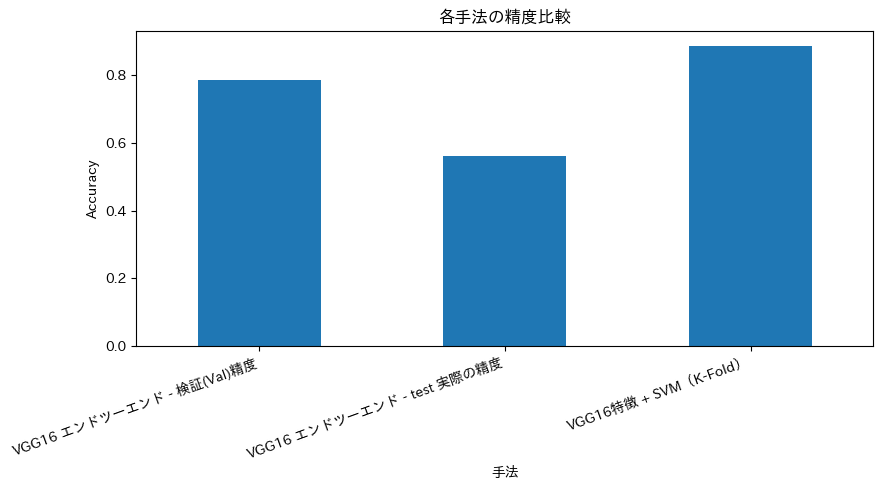

In [ ]:
comparison_results = {
    'VGG16 エンドツーエンド - 検証(Val)精度': best_val_acc,
    'VGG16 エンドツーエンド - test 実際の精度': test_accuracy,
    'VGG16特徴 + SVM（K-Fold）': cv_scores_vgg.mean(),
    # 他の対照実験を追加する場合はここに追記
}

comparison_df = pd.DataFrame(list(comparison_results.items()), columns=['手法', '精度'])
print(comparison_df)

comparison_df.plot(x='手法', y='精度', kind='bar', legend=False, figsize=(9, 5))
plt.ylabel('Accuracy')
plt.title('各手法の精度比較')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.savefig('method_comparison.png', dpi=100)
plt.show()


## まとめ
- 本課題は「テクスチャ／素材認識（Texture / Material Classification）」タスクであり、50クラス・各クラス12枚という
  極めて少ないサンプル数が最大の課題であった。
- VGG16を特徴抽出器としてのみ使用し、SVMで分類する「ハイブリッド手法」も試した。エンドツーエンドで学習する
  分類ヘッド（神経網路）と、SVMという異なる分類器を比較することで、性能差が「特徴量の質」によるものか
  「分類器の過学習しやすさ」によるものかを切り分けて考察できる。
- 学習済みモデルの重み、学習曲線、混同行列、testデータの予測結果はすべて保存済みであり、レポート作成に利用できる。
